## Performance Data & Plots

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

## 1. Baseline (v0.0): Compiler Flags & Partition Comparison

In [3]:
df_baseline = pd.DataFrame({
    'n': [100, 500, 1000, 2000],
    'O0_cclake_avg':       [0.001349, 0.241487, 1.789275, 18.820313],
    'O0_cclake_std':       [0.000018, 0.002526, 0.027989, 0.039889],
    'O0_icelake_avg':      [0.000909, 0.148377, 1.204476, 12.432337],
    'O0_icelake_std':      [0.000011, 0.000217, 0.008305, 0.088256],
    'O3xHost_cclake_avg':  [0.000281, 0.068460, 0.624417, 6.697941],
    'O3xHost_cclake_std':  [0.000007, 0.000121, 0.001260, 0.024784],
    'O3xHost_icelake_avg': [0.000187, 0.038122, 0.425013, 5.468103],
    'O3xHost_icelake_std': [0.000004, 0.000189, 0.000636, 0.028597],
})
df_baseline

,n,O0_cclake_avg,O0_cclake_std,O0_icelake_avg,O0_icelake_std,O3xHost_cclake_avg,O3xHost_cclake_std,O3xHost_icelake_avg,O3xHost_icelake_std
0,100,0.001349,0.000018,0.000909,0.000011,0.000281,0.000007,0.000187,0.000004
1,500,0.241487,0.002526,0.148377,0.000217,0.068460,0.000121,0.038122,0.000189
2,1000,1.789275,0.027989,1.204476,0.008305,0.624417,0.001260,0.425013,0.000636
3,2000,18.820313,0.039889,12.432337,0.088256,6.697941,0.024784,5.468103,0.028597


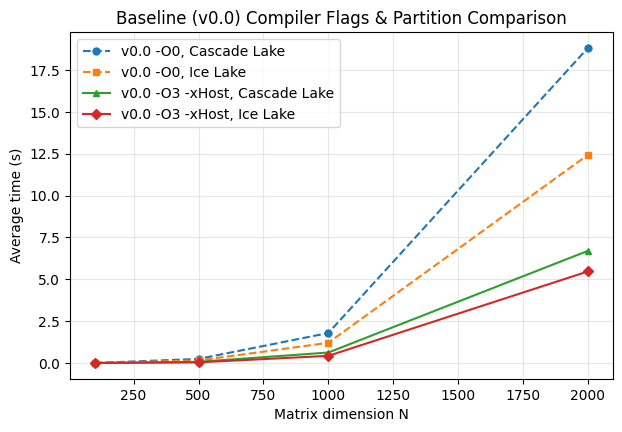

In [4]:
# Baseline compiler flag and partition comparison
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(df_baseline['n'], df_baseline['O0_cclake_avg'],       'o--', label='v0.0 -O0, Cascade Lake', markersize=5)
ax.plot(df_baseline['n'], df_baseline['O0_icelake_avg'],      's--', label='v0.0 -O0, Ice Lake', markersize=5)
ax.plot(df_baseline['n'], df_baseline['O3xHost_cclake_avg'],  '^-',  label='v0.0 -O3 -xHost, Cascade Lake', markersize=5)
ax.plot(df_baseline['n'], df_baseline['O3xHost_icelake_avg'], 'D-',  label='v0.0 -O3 -xHost, Ice Lake', markersize=5)

ax.set_xlabel('Matrix dimension N')
ax.set_ylabel('Average time (s)')
ax.set_title('Baseline (v0.0) Compiler Flags & Partition Comparison')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

## 2. Single-Threaded Optimisation Series (v0.0-v0.4)

All on Ice Lake, -O3 -xHost, OMP_NUM_THREADS=1.

In [5]:
# v0.0 baseline (-O3 -xHost, Ice Lake)
df_v00 = pd.DataFrame({
    'n':   [100, 500, 1000, 2000],
    'avg': [0.000187, 0.038122, 0.425013, 5.468103],
    'std': [0.000004, 0.000189, 0.000636, 0.028597],
})

# v0.1
df_v01 = pd.DataFrame({
    'n':   [100, 500, 1000, 2000, 3000, 4000, 5000],
    'avg': [0.000121, 0.017316, 0.147296, 1.436534, 6.523808, 17.368254, 35.845882],
    'std': [0.000002, 0.000185, 0.000227, 0.039501, 0.079054, 0.056339,  0.553149],
})

# v0.2
df_v02 = pd.DataFrame({
    'n':   [100, 500, 1000, 2000, 3000, 4000, 5000],
    'avg': [0.000135, 0.018777, 0.159000, 1.329503, 6.133880, 16.824307, 34.840939],
    'std': [0.000003, 0.000100, 0.000406, 0.005937, 0.055720, 0.069455,  0.063529],
})

# v0.3
df_v03 = pd.DataFrame({
    'n':   [100, 500, 1000, 2000, 3000, 4000, 5000, 8000],
    'avg': [0.000071, 0.009527, 0.085346, 0.663676, 2.579256, 7.421129, 16.386453, 76.491817],
    'std': [0.000002, 0.000130, 0.000331, 0.001100, 0.075275, 0.009192, 0.200771,  0.067520],
})

# v0.4
df_v04 = pd.DataFrame({
    'n':   [100, 500, 1000, 2000, 3000, 4000, 5000, 8000, 10000, 15000],
    'avg': [0.000039, 0.004924, 0.056283, 0.450845, 1.618427, 5.650543, 13.164208, 61.548106, 122.821552, 414.014815],
    'std': [0.000002, 0.000027, 0.000287, 0.001358, 0.036542, 0.149379, 0.204666,  0.388576,  0.548808,   1.533023],
})

print('=== v0.0 (baseline, -O3 -xHost, Ice Lake) ===')
display(df_v00)
print('\n=== v0.1 ===')
display(df_v01)
print('\n=== v0.2 ===')
display(df_v02)
print('\n=== v0.3 ===')
display(df_v03)
print('\n=== v0.4 ===')
display(df_v04)

=== v0.0 (baseline, -O3 -xHost, Ice Lake) ===


,n,avg,std
0,100,0.000187,0.000004
1,500,0.038122,0.000189
2,1000,0.425013,0.000636
3,2000,5.468103,0.028597



=== v0.1 ===


,n,avg,std
0,100,0.000121,0.000002
1,500,0.017316,0.000185
2,1000,0.147296,0.000227
3,2000,1.436534,0.039501
4,3000,6.523808,0.079054
5,4000,17.368254,0.056339
6,5000,35.845882,0.553149



=== v0.2 ===


,n,avg,std
0,100,0.000135,0.000003
1,500,0.018777,0.000100
2,1000,0.159000,0.000406
3,2000,1.329503,0.005937
4,3000,6.133880,0.055720
5,4000,16.824307,0.069455
6,5000,34.840939,0.063529



=== v0.3 ===


,n,avg,std
0,100,0.000071,0.000002
1,500,0.009527,0.000130
2,1000,0.085346,0.000331
3,2000,0.663676,0.001100
4,3000,2.579256,0.075275
5,4000,7.421129,0.009192
6,5000,16.386453,0.200771
7,8000,76.491817,0.067520



=== v0.4 ===


,n,avg,std
0,100,0.000039,0.000002
1,500,0.004924,0.000027
2,1000,0.056283,0.000287
3,2000,0.450845,0.001358
4,3000,1.618427,0.036542
5,4000,5.650543,0.149379
6,5000,13.164208,0.204666
7,8000,61.548106,0.388576
8,10000,122.821552,0.548808
9,15000,414.014815,1.533023


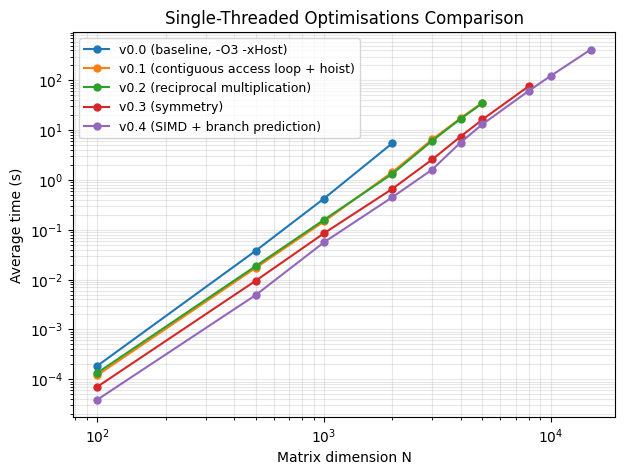

In [6]:
# Single-threaded optimisations comparison (log-scale on both axes for clearer visualisation)
fig, ax = plt.subplots(figsize=(7, 5))

ax.loglog(df_v00['n'], df_v00['avg'], 'o-',  label='v0.0 (baseline, -O3 -xHost)', markersize=5)
ax.loglog(df_v01['n'], df_v01['avg'], 'o-',  label='v0.1 (contiguous access loop + hoist)', markersize=5)
ax.loglog(df_v02['n'], df_v02['avg'], 'o-',  label='v0.2 (reciprocal multiplication)', markersize=5)
ax.loglog(df_v03['n'], df_v03['avg'], 'o-',  label='v0.3 (symmetry)', markersize=5)
ax.loglog(df_v04['n'], df_v04['avg'], 'o-',  label='v0.4 (SIMD + branch prediction)', markersize=5)

ax.set_xlabel('Matrix dimension N')
ax.set_ylabel('Average time (s)')
ax.set_title('Single-Threaded Optimisations Comparison')
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3, which='both')
plt.show()

## 3. Multi-Threads (v1.1) Scheduler & Thread Tuning

All at n = 10,000, Ice Lake, 76 cores available, -O3 -xHost.

In [15]:
df_v11_tuning = pd.DataFrame({
    'threads': [1, 8, 32, 56, 76],
    'static32_avg':  [111.610753, 19.438303, 12.582102, 11.069679, 9.876339],
    'static32_std':  [15.080022,  1.523426,  0.385889,  0.267170,  0.332887],
    'dynamic16_avg': [111.653103, 17.037528, 12.332675, 11.399070, 10.900135],
    'dynamic16_std': [15.185514,  0.825168,  0.295768,  0.088252,  0.028289],
    'dynamic32_avg': [111.836048, 17.162247, 12.481013, 11.606595, 11.175527],
    'dynamic32_std': [15.526158,  0.705869,  0.438897,  0.270541,  0.034830],
    'guided16_avg':  [111.120317, 21.699841, 16.315452, 14.995799, 14.498527],
    'guided16_std':  [14.076440,  0.482393,  0.660600,  0.076574,  0.029829],
})
df_v11_tuning

,threads,static32_avg,static32_std,dynamic16_avg,dynamic16_std,dynamic32_avg,dynamic32_std,guided16_avg,guided16_std
0,1,111.610753,15.080022,111.653103,15.185514,111.836048,15.526158,111.120317,14.076440
1,8,19.438303,1.523426,17.037528,0.825168,17.162247,0.705869,21.699841,0.482393
2,32,12.582102,0.385889,12.332675,0.295768,12.481013,0.438897,16.315452,0.660600
3,56,11.069679,0.267170,11.399070,0.088252,11.606595,0.270541,14.995799,0.076574
4,76,9.876339,0.332887,10.900135,0.028289,11.175527,0.034830,14.498527,0.029829


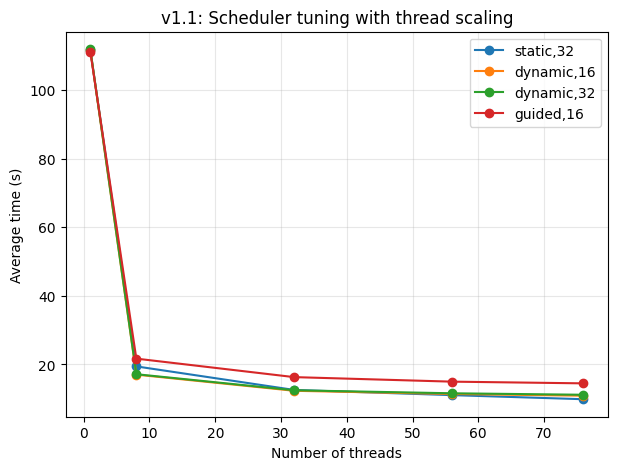

In [38]:
# Thread scaling for different scheduling configs
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(df_v11_tuning['threads'], df_v11_tuning['static32_avg'],  'o-', label='static,32')
ax.plot(df_v11_tuning['threads'], df_v11_tuning['dynamic16_avg'], 'o-', label='dynamic,16')
ax.plot(df_v11_tuning['threads'], df_v11_tuning['dynamic32_avg'], 'o-', label='dynamic,32')
ax.plot(df_v11_tuning['threads'], df_v11_tuning['guided16_avg'],  'o-', label='guided,16')

ax.set_xlabel('Number of threads')
ax.set_ylabel('Average time (s)')
ax.set_title('v1.1: Scheduler tuning with thread scaling')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

In [39]:
# # Figure 5: Speedup vs ideal (static,32)
# fig, ax = plt.subplots(figsize=(7, 4.5))

# t1 = df_v11_tuning['static32_avg'].iloc[0]  # single-thread time
# speedup = t1 / df_v11_tuning['static32_avg']
# threads = df_v11_tuning['threads']

# ax.plot(threads, speedup, 'o-', label='static,32 (actual)', markersize=6)
# ax.plot(threads, threads, 'k--', label='Ideal speedup', alpha=0.5)

# ax.set_xlabel('Number of OpenMP threads')
# ax.set_ylabel('Speedup')
# ax.set_title('Figure 5: Parallel Speedup vs Ideal (n = 10000, v1.1, static,32)')
# ax.legend()
# ax.grid(True, alpha=0.3)
# # savefig(fig, 'fig5_speedup_ideal.png')
# plt.show()

## 4. Multi-Threads (v1.1) Matrix dimension scaling at optimal configuration, compared with the best single-thread performance (v0.4)

In [52]:
# v1.1 optimal (76 threads, static,32)
df_v11_optimal = pd.DataFrame({
    'n':   [100, 500, 1000, 2000, 3000, 4000, 5000, 8000, 10000, 15000],
    'avg': [0.046608, 0.204882, 0.371845, 0.512459, 0.601800, 0.526178, 0.320682, 2.454264, 9.989285, 58.706428],
    'std': [0.013553, 0.002198, 0.038283, 0.057960, 0.016703, 0.317555, 0.007552, 0.046874, 0.009274, 0.154474],
})

# Combined: v0.4 vs v1.1
df_final = pd.merge(df_v04, df_v11_optimal, on='n', suffixes=('_v04', '_v11'), how='outer')
df_final['speedup'] = df_final['avg_v04'] / df_final['avg_v11']
df_final = df_final.rename(columns={
    'avg_v04': 'v0.4_avg', 'std_v04': 'v0.4_std',
    'avg_v11': 'v1.1_avg', 'std_v11': 'v1.1_std',
})
df_final

,n,v0.4_avg,v0.4_std,v1.1_avg,v1.1_std,speedup
0,100,0.000039,0.000002,0.046608,0.013553,0.000837
1,500,0.004924,0.000027,0.204882,0.002198,0.024033
2,1000,0.056283,0.000287,0.371845,0.038283,0.151361
3,2000,0.450845,0.001358,0.512459,0.057960,0.879768
4,3000,1.618427,0.036542,0.601800,0.016703,2.689310
5,4000,5.650543,0.149379,0.526178,0.317555,10.738843
6,5000,13.164208,0.204666,0.320682,0.007552,41.050661
7,8000,61.548106,0.388576,2.454264,0.046874,25.078030
8,10000,122.821552,0.548808,9.989285,0.009274,12.295330
9,15000,414.014815,1.533023,58.706428,0.154474,7.052291


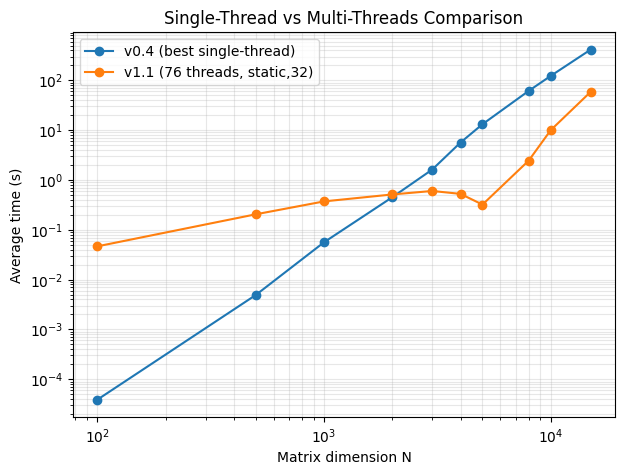

In [51]:
# Single-thread (v0.4) vs multi-thread (v1.1) comparison (both axes on log scale - for clearer visualisation)
fig, ax = plt.subplots(figsize=(7, 5))

ax.loglog(df_v04['n'], df_v04['avg'], 'o-',  label='v0.4 (best single-thread)')
ax.loglog(df_v11_optimal['n'], df_v11_optimal['avg'], 'o-', label='v1.1 (76 threads, static,32)')

ax.set_xlabel('Matrix dimension N')
ax.set_ylabel('Average time (s)')
ax.set_title('Single-Thread vs Multi-Threads Comparison')
ax.legend()
ax.grid(True, alpha=0.3, which='both')
plt.show()

## 5. Combined Single-Threaded Summary Table

All versions with avg ± std, on Ice Lake, -O3 -xHost, 1 thread. For use in report Table 2.

In [21]:
# Build a combined table with all single-threaded versions
all_n = sorted(set(
    df_v00['n'].tolist() + df_v01['n'].tolist() + df_v02['n'].tolist() +
    df_v03['n'].tolist() + df_v04['n'].tolist()
))

def make_lookup(df):
    return {row['n']: (row['avg'], row['std']) for _, row in df.iterrows()}

lookups = {
    'v0.0': make_lookup(df_v00),
    'v0.1': make_lookup(df_v01),
    'v0.2': make_lookup(df_v02),
    'v0.3': make_lookup(df_v03),
    'v0.4': make_lookup(df_v04),
}

rows = []
for n in all_n:
    row = {'n': n}
    for vname, lookup in lookups.items():
        if n in lookup:
            avg, std = lookup[n]
            row[f'{vname}_avg'] = avg
            row[f'{vname}_std'] = std
        else:
            row[f'{vname}_avg'] = None
            row[f'{vname}_std'] = None
    rows.append(row)

df_all_single = pd.DataFrame(rows)
df_all_single

,n,v0.0_avg,v0.0_std,v0.1_avg,v0.1_std,v0.2_avg,v0.2_std,v0.3_avg,v0.3_std,v0.4_avg,v0.4_std
0,100,0.000187,0.000004,0.000121,0.000002,0.000135,0.000003,0.000071,0.000002,0.000039,0.000002
1,500,0.038122,0.000189,0.017316,0.000185,0.018777,0.000100,0.009527,0.000130,0.004924,0.000027
2,1000,0.425013,0.000636,0.147296,0.000227,0.159000,0.000406,0.085346,0.000331,0.056283,0.000287
3,2000,5.468103,0.028597,1.436534,0.039501,1.329503,0.005937,0.663676,0.001100,0.450845,0.001358
4,3000,NaN,NaN,6.523808,0.079054,6.133880,0.055720,2.579256,0.075275,1.618427,0.036542
5,4000,NaN,NaN,17.368254,0.056339,16.824307,0.069455,7.421129,0.009192,5.650543,0.149379
6,5000,NaN,NaN,35.845882,0.553149,34.840939,0.063529,16.386453,0.200771,13.164208,0.204666
7,8000,NaN,NaN,NaN,NaN,NaN,NaN,76.491817,0.067520,61.548106,0.388576
8,10000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,122.821552,0.548808
9,15000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,414.014815,1.533023
